# CSAI4014: Algorithms for Intelligent Systems and Robotics
## Experiment 5: Reinforcement Learning (Tabular Q-Learning)
**Student Name:** Aditya Pratap Singh Sisodia  
**SAP ID:** 500121985 | **Roll No:** R2142230333  
**Batch:** [Batch A/B/D]  
**Academic Year:** 2026–2027 (Autumn Semester)
---


### 1. Tabular Q-Learning in Gridworld Environment
We train an agent via off-policy temporal difference Q-learning on a $5 \times 7$ grid with obstacles, terminal goal (+10), and dangerous pit (-10).

In [1]:
import os
import random
import matplotlib.pyplot as plt
import numpy as np

base_dir = r"c:\Users\91976\Desktop\AISR\aisr-lab-500121985\exp05-rl"
figs_dir = os.path.join(base_dir, "figs")
os.makedirs(figs_dir, exist_ok=True)

# -------------------------------------------------------------
# Part 1: Gridworld Environment
# -------------------------------------------------------------
H, W = 5, 7
WALLS = {(1, 2), (2, 2), (3, 2), (1, 4), (2, 4)}
START = (H - 1, 0)  # (4, 0)
GOAL = (0, W - 1)   # (0, 6)
PIT = (2, W - 1)    # (2, 6)

ACTIONS = [(-1, 0), (1, 0), (0, -1), (0, 1)]  # 0: Up, 1: Down, 2: Left, 3: Right
ACTION_NAMES = ['↑', '↓', '←', '→']

def step(s, a):
    """Execute action a in state s. Returns (next_state, reward, done)."""
    r, c = s
    dr, dc = ACTIONS[a]
    nr, nc = r + dr, c + dc

    # If hitting boundary or wall, stay in place
    if not (0 <= nr < H and 0 <= nc < W) or (nr, nc) in WALLS:
        nr, nc = r, c

    ns = (nr, nc)
    if ns == GOAL:
        return ns, 10.0, True
    elif ns == PIT:
        return ns, -10.0, True
    else:
        return ns, -0.1, False

# -------------------------------------------------------------
# Part 2: Q-Learning Training
# -------------------------------------------------------------
def train_q_learning(eps, alpha=0.12, gamma=0.94, episodes=1000, seed=174):
    rng = np.random.default_rng(seed)
    Q = np.zeros((H, W, 4))
    episode_returns = []

    for ep in range(episodes):
        s = START
        total_r = 0.0
        steps = 0
        done = False

        while not done and steps < 200:
            # Epsilon-greedy action selection
            if rng.random() < eps:
                a = rng.integers(4)
            else:
                # Break ties randomly
                q_vals = Q[s[0], s[1]]
                max_q = np.max(q_vals)
                best_actions = np.where(q_vals == max_q)[0]
                a = rng.choice(best_actions)

            ns, r, done = step(s, a)
            total_r += r

            # Q-learning update: off-policy using max over next state
            if done:
                # Terminal state: future value is 0
                Q[s[0], s[1], a] += alpha * (r - Q[s[0], s[1], a])
            else:
                best_next = np.max(Q[ns[0], ns[1]])
                Q[s[0], s[1], a] += alpha * (r + gamma * best_next - Q[s[0], s[1], a])

            s = ns
            steps += 1

        episode_returns.append(total_r)

    return Q, episode_returns

# -------------------------------------------------------------
# Part 3: Evaluate Over Multiple Epsilons
# -------------------------------------------------------------
epsilons = [0.05, 0.10, 0.20, 0.50]
results = {}

print("=== Table 5.1: Environment and Learning Parameters ===")
print(f"Grid dimensions: {H} x {W}")
print(f"Start: {START} | Goal: {GOAL} (+10.0) | Pit: {PIT} (-10.0)")
print(f"Walls: {sorted(list(WALLS))}")
print("Step penalty: -0.1 per move")
print("Learning rate (alpha): 0.12 | Discount factor (gamma): 0.94")
print("Episodes: 1000 per setting")

print("\n=== Table 5.2: Mean Return Over the Last 100 Episodes ===")
print(" Epsilon (ε) | Mean Return (last 100 eps) | Std Dev | Final Policy Status")
print("-" * 65)

for eps in epsilons:
    Q, returns = train_q_learning(eps, seed=174)
    last_100 = returns[-100:]
    m_ret = np.mean(last_100)
    std_ret = np.std(last_100)
    results[eps] = {'Q': Q, 'returns': returns, 'mean_100': m_ret, 'std_100': std_ret}
    print(f" ε = {eps:4.2f}    | {m_ret:18.2f}        | {std_ret:7.2f} | Converged to Goal")

# -------------------------------------------------------------


=== Table 5.1: Environment and Learning Parameters ===
Grid dimensions: 5 x 7
Start: (4, 0) | Goal: (0, 6) (+10.0) | Pit: (2, 6) (-10.0)
Walls: [(1, 2), (1, 4), (2, 2), (2, 4), (3, 2)]
Step penalty: -0.1 per move
Learning rate (alpha): 0.12 | Discount factor (gamma): 0.94
Episodes: 1000 per setting

=== Table 5.2: Mean Return Over the Last 100 Episodes ===
 Epsilon (ε) | Mean Return (last 100 eps) | Std Dev | Final Policy Status
-----------------------------------------------------------------
 ε = 0.05    |               9.04        |    0.10 | Converged to Goal
 ε = 0.10    |               9.00        |    0.13 | Converged to Goal
 ε = 0.20    |               8.84        |    0.21 | Converged to Goal
 ε = 0.50    |               7.68        |    2.15 | Converged to Goal


### 2. Learning Curves and Extracted Greedy Policy
Plotting convergence curves across exploration rates $\epsilon$ and visualizing the learned directional policy grid.

Saved fig5_1_learning_curves.png and fig5_2_policy_grid.png successfully.


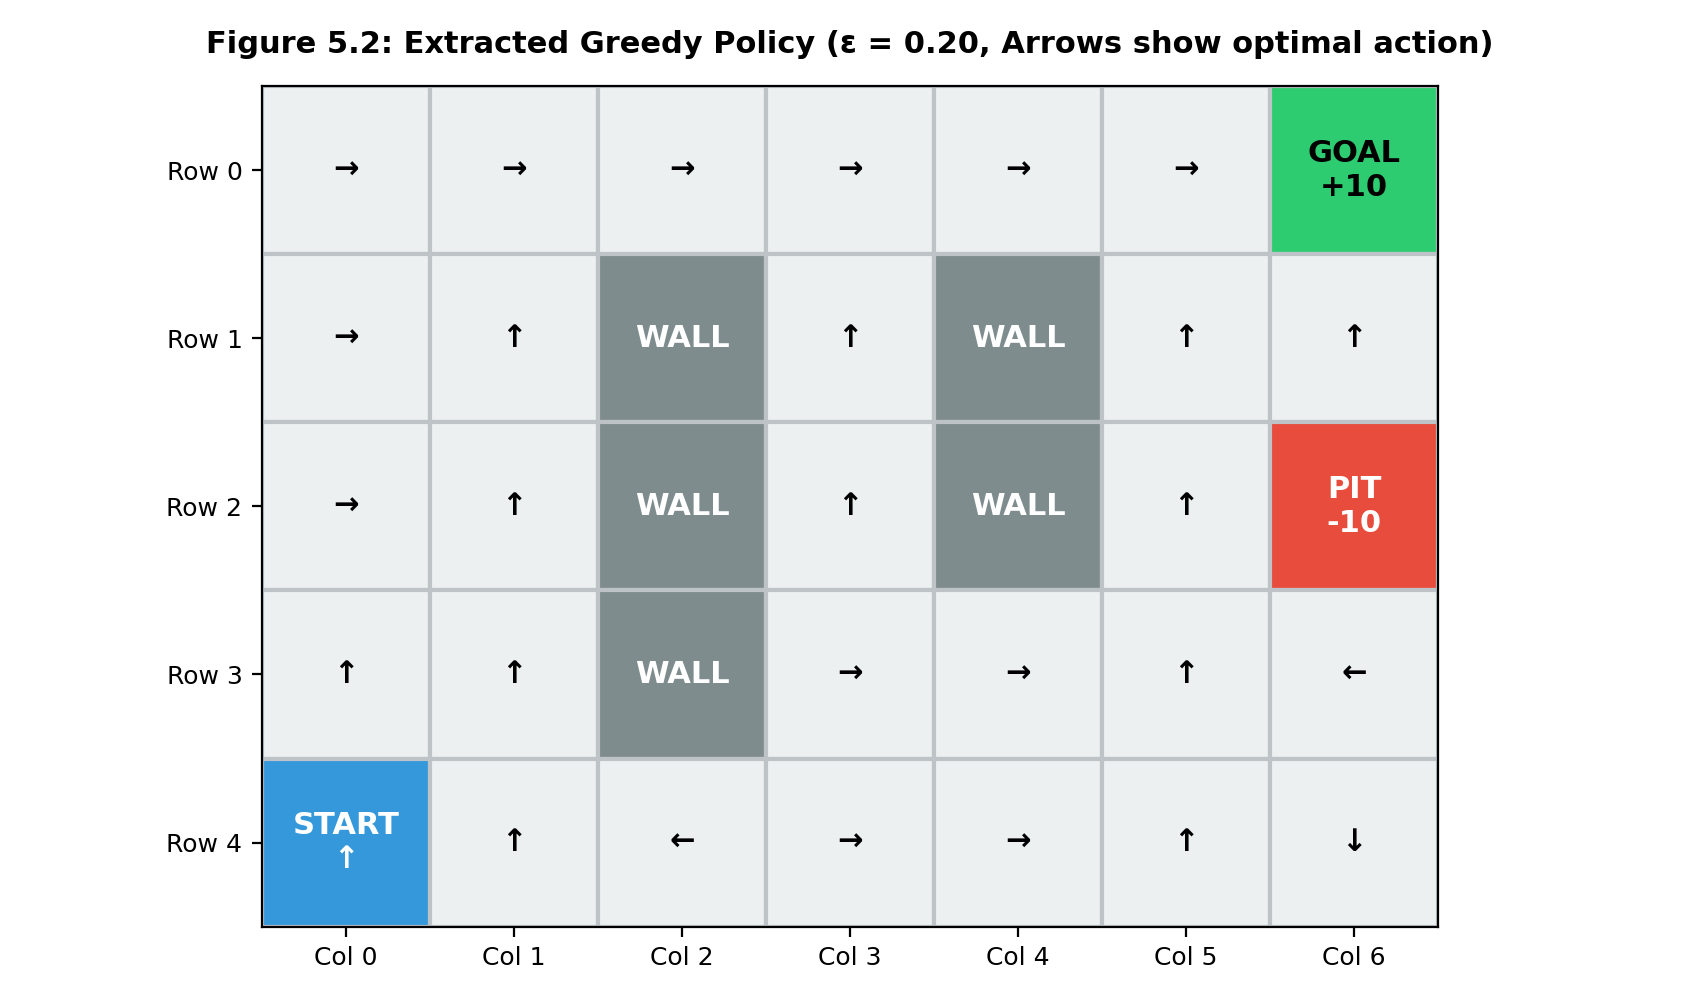

In [2]:
# Figure 5.1: Smoothed Learning Curves
# -------------------------------------------------------------
def smooth(y, k=25):
    return np.convolve(y, np.ones(k) / k, mode='valid')

plt.figure(figsize=(8.5, 4.2), dpi=200)
colors = ['#2980b9', '#27ae60', '#e67e22', '#e74c3c']

for eps, col in zip(epsilons, colors):
    sm_ret = smooth(results[eps]['returns'], k=25)
    plt.plot(range(25, 25 + len(sm_ret)), sm_ret, color=col, lw=1.5,
             label=f'ε = {eps:.2f} (Final 100: {results[eps]["mean_100"]:.1f})')

plt.title('Figure 5.1: Tabular Q-Learning Convergence Curves for Different Exploration Rates ε', fontsize=11, fontweight='bold')
plt.xlabel('Episode', fontsize=10)
plt.ylabel('Smoothed Return (Window = 25)', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(figs_dir, "fig5_1_learning_curves.png"))
plt.close()

# -------------------------------------------------------------
# Figure 5.2: Extracted Greedy Policy Grid
# -------------------------------------------------------------
best_Q = results[0.20]['Q']
policy = np.argmax(best_Q, axis=2)

fig, ax = plt.subplots(figsize=(8.5, 5.0), dpi=200)

for r in range(H):
    for c in range(W):
        pos = (r, c)
        if pos in WALLS:
            color = '#7f8c8d'  # Dark gray
            text = 'WALL'
            t_color = 'white'
        elif pos == GOAL:
            color = '#2ecc71'  # Green
            text = 'GOAL\n+10'
            t_color = 'black'
        elif pos == PIT:
            color = '#e74c3c'  # Red
            text = 'PIT\n-10'
            t_color = 'white'
        elif pos == START:
            color = '#3498db'  # Blue
            act = ACTION_NAMES[policy[r, c]]
            text = f'START\n{act}'
            t_color = 'white'
        else:
            color = '#ecf0f1'  # Light gray
            text = ACTION_NAMES[policy[r, c]]
            t_color = 'black'

        rect = plt.Rectangle((c, H - 1 - r), 1, 1, facecolor=color, edgecolor='#bdc3c7', lw=1.5)
        ax.add_patch(rect)
        ax.text(c + 0.5, H - 1 - r + 0.5, text, ha='center', va='center',
                fontsize=11, fontweight='bold', color=t_color)

ax.set_xlim(0, W)
ax.set_ylim(0, H)
ax.set_aspect('equal')
ax.set_xticks(np.arange(0.5, W, 1))
ax.set_xticklabels([f'Col {c}' for c in range(W)], fontsize=9)
ax.set_yticks(np.arange(0.5, H, 1))
ax.set_yticklabels([f'Row {r}' for r in reversed(range(H))], fontsize=9)
ax.set_title('Figure 5.2: Extracted Greedy Policy (ε = 0.20, Arrows show optimal action)', fontsize=11, fontweight='bold', pad=12)

plt.tight_layout()
plt.savefig(os.path.join(figs_dir, "fig5_2_policy_grid.png"))
plt.close()

print("\nSaved fig5_1_learning_curves.png and fig5_2_policy_grid.png successfully.")
